In [1]:
import mne
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import warnings
import sys

sys.path.append('/Users/qmoreau/Documents/ERN_sim/lagged_hilbert_autocoherence/python')
from woody_filter import woody, woody_stochastic
from lagged_autocoherence import lagged_hilbert_autocoherence

warnings.filterwarnings('ignore')

data_dir = Path('/Users/qmoreau/Documents/ERN_sim/N2pipeline/cong_incong_epochs')

subjects = [
    'sub-AH17AR05', 'sub-AI09ID16', 'sub-AL07NK06', 'sub-AL08AS02',
    'sub-AR06AS06', 'sub-AR10IO04', 'sub-AT06ED25', 'sub-AU09GE22',
    'sub-CH04ER19', 'sub-CH05NK28', 'sub-CH06UT07', 'sub-CH07AD15',
    'sub-CH07NK17', 'sub-CH07RK18', 'sub-CH10NG24', 'sub-CK04NS18',
    'sub-CK05EN08', 'sub-CK06ED08', 'sub-CK06US15', 'sub-CK07NK21',
    'sub-DADARE11', 'sub-DS08NK08', 'sub-DT05AH09', 'sub-DT05EV26',
    'sub-DT07ES22', 'sub-DTINTZ10', 'sub-EA06ER02', 'sub-EK05AN14',
    'sub-EK06ER26', 'sub-EK07CH24', 'sub-EL04AM03', 'sub-EL05JO26',
    'sub-EL06EL11', 'sub-EL06LD17', 'sub-EL06ST21', 'sub-EL07EL14',
    'sub-EN04ER01', 'sub-EN04ER14', 'sub-EN05AN02', 'sub-EN05ED14',
    'sub-EN05KT02', 'sub-EN05US05', 'sub-EN06AN21', 'sub-EN08CH27',
    'sub-EP05EN09', 'sub-ER03ER09', 'sub-ER03LF17', 'sub-ER04CH03',
    'sub-ER04ER12', 'sub-ER04RT24', 'sub-ER04ST03', 'sub-ER05AN13',
    'sub-ER05AR27', 'sub-ER05AS20', 'sub-ER05AV01', 'sub-ER05EL09',
    'sub-ER05EL26', 'sub-ER05ER07', 'sub-ER05IM29', 'sub-ER05MA17',
    'sub-ER05NG11', 'sub-ER05RI09', 'sub-ER05RK06', 'sub-ER05RT24',
    'sub-ER06AN07', 'sub-ER06AN28', 'sub-ER06EF14', 'sub-ER06EL06',
    'sub-ER06EN03', 'sub-ER06EN27', 'sub-ER06ET15', 'sub-ER06IM15',
    'sub-ER06IS22', 'sub-ER06KR20', 'sub-ER06NK09', 'sub-ER06US24',
    'sub-ER07AS24', 'sub-ER07EF15', 'sub-ER07EN04', 'sub-ER07ER23',
    'sub-ER07ER30', 'sub-ER07ND12', 'sub-ER07RL02', 'sub-ER08AH23',
    'sub-ER08AS28', 'sub-ER08EN05', 'sub-ER08ER03', 'sub-ER08RT29',
    'sub-ER09DO22', 'sub-ER09NK30', 'sub-ER09NZ11', 'sub-ER10IG12',
    'sub-ES06ER27', 'sub-ES06NK11', 'sub-EV06AN16', 'sub-EZ04SE15',
    'sub-FA04HU23', 'sub-FE06AN24', 'sub-GA04LI18', 'sub-GA06OF10',
    'sub-GY06LO26', 'sub-HEERLD19', 'sub-HL09AN11', 'sub-HR07ED31',
    'sub-IA05NS20', 'sub-ID07EN28', 'sub-IG06LF01', 'sub-IG06NS07',
    'sub-IG06WE03', 'sub-IG07RT16', 'sub-IK06ET06', 'sub-IK09LD05',
    'sub-IN05ED23', 'sub-IN06AS14', 'sub-IN07ET30', 'sub-IR04ET20',
    'sub-IS06RG09', 'sub-IT08ND26', 'sub-JA06AS11', 'sub-JU05IN24',
    'sub-KA04LF11', 'sub-KE04NI10', 'sub-KE05AN23', 'sub-KE06EL16',
    'sub-KE07AN05', 'sub-KE07ER04', 'sub-KE08AS23', 'sub-KI05US17',
    'sub-KN05EN09', 'sub-KO07EL16', 'sub-LA08RE26', 'sub-LE04ON09',
    'sub-LF04AS01', 'sub-LF07RT29', 'sub-LO06RE10', 'sub-LY07EL23',
    'sub-MA06LO21', 'sub-ME05NS04', 'sub-MI07AH25', 'sub-NA04AV25',
    'sub-NA04OV25', 'sub-ND05NG06', 'sub-ND06EF01', 'sub-NE06AS01',
    'sub-NE06AS31', 'sub-NE06EL01', 'sub-NG03YI17', 'sub-NG05AS30',
    'sub-NG06NI21', 'sub-NG06UL04', 'sub-NG07AN22', 'sub-NK06AS24',
    'sub-NK06RG30', 'sub-NN04AN24', 'sub-NN05AN05', 'sub-NN05IR17',
    'sub-NN06TH16', 'sub-NN06US23', 'sub-NN07EN14', 'sub-NN07ID18',
    'sub-NN08AS03', 'sub-NN08EL29', 'sub-NN08ER22', 'sub-NN08LM06',
    'sub-NN09LM18', 'sub-NN09NS31', 'sub-NO05RT22', 'sub-NS05RO15',
    'sub-NS09EL05', 'sub-NY04DT26', 'sub-NZ04EN16', 'sub-NZ09ER04',
    'sub-OH05NK29', 'sub-ON05EL22', 'sub-ON06US07', 'sub-OW07RK26',
    'sub-PP07AS29', 'sub-RASUAN07', 'sub-RF09EL18', 'sub-RG05AS08',
    'sub-RG06AS09', 'sub-RG07US04', 'sub-RN10AN23', 'sub-RS06RS22',
    'sub-RS07LF20', 'sub-RT04KE01', 'sub-RT05EL10', 'sub-RT06AN02',
    'sub-RT07LD06', 'sub-RZ05ND19', 'sub-SE05EN28', 'sub-SE05ZI24',
    'sub-SE06AM29', 'sub-SE06NS17', 'sub-SS04PH05', 'sub-ST03ED03',
    'sub-ST07NK15', 'sub-TA03RL11', 'sub-TE03AS11', 'sub-TE05AS09',
    'sub-TE05NS01', 'sub-TE08IO29', 'sub-TE10AN12', 'sub-TH07AR12',
    'sub-TL08AN16', 'sub-TT08NS17', 'sub-TZ08US31', 'sub-UN07AS25',
    'sub-US05RK06', 'sub-US07US10', 'sub-US08KE27', 'sub-VA03ER17',
    'sub-VA05AS27', 'sub-VA05ER28', 'sub-VA05OR26', 'sub-VA06EY24',
    'sub-VA06NZ29', 'sub-VA06OV12', 'sub-WA04EJ22', 'sub-WA05EJ08',
    'sub-XX04AS28'
]

In [2]:
def align_trials(trials, lags):
    n_trials, n_times = trials.shape
    aligned = np.zeros_like(trials)
    for i in range(n_trials):
        lag = lags[i]
        if lag > 0:
            aligned[i, :] = np.concatenate([trials[i, lag:], np.zeros(lag)])
        elif lag < 0:
            aligned[i, :] = np.concatenate([np.zeros(-lag), trials[i, :lag]])
        else:
            aligned[i, :] = trials[i, :]
    return aligned

def regress_erp(trials, erp):
    regressed = np.zeros_like(trials)
    for i in range(trials.shape[0]):
        slope, intercept, _, _, _ = linregress(erp, trials[i, :])
        regressed[i, :] = trials[i, :] - (intercept + slope * erp)
    return regressed

def compute_tfr(trials, freqs, sfreq):
    n_trials, n_times = trials.shape
    n_cycles = freqs / 2.0
    tfr = np.zeros((len(freqs), n_times))
    for trial in range(n_trials):
        for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
            wavelet_duration = min(3 * n_cycle / freq, 0.5)
            wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
            wavelet = np.exp(2j * np.pi * freq * wavelet_time) * np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
            convolved = np.convolve(trials[trial, :], wavelet, mode='same')
            tfr[idx, :] += np.abs(convolved) ** 2
    return tfr / n_trials

def baseline_correct(tfr, times, bl_window=(-0.5, 0)):
    bl_mask = (times >= bl_window[0]) & (times <= bl_window[1])
    bl = tfr[:, bl_mask].mean(axis=1, keepdims=True)
    return ((tfr - bl) / bl) * 100

def extract_theta(tfr_pct, freqs, times, theta_range=(4, 8), time_window=(0, 0.5)):
    theta_mask = (freqs >= theta_range[0]) & (freqs <= theta_range[1])
    time_mask = (times >= time_window[0]) & (times <= time_window[1])
    return tfr_pct[theta_mask, :][:, time_mask].mean()

In [3]:
def analyze_subject(epochs_path, trial_type='incongruent', channel='FZ'):
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    if trial_type == 'incongruent':
        codes = ['104']
    else:
        codes = ['134']
    
    epochs_sel = epochs[codes]
    n_trials = len(epochs_sel)
    if n_trials < 5:
        return None
    
    data = epochs_sel.copy().pick([channel]).get_data()[:, 0, :] * 1e6
    times = epochs_sel.times
    sfreq = epochs_sel.info['sfreq']
    freqs = np.arange(4, 30, 0.5)
    
    # Raw
    erp_raw = data.mean(axis=0)
    induced_raw = data - erp_raw
    tfr_raw = baseline_correct(compute_tfr(induced_raw, freqs, sfreq), times)
    
    # Woody
    _, lags_w = woody(data.T, tol=0.1, max_it=100, est_mthd='woody', xcorr_mthd='unbiased', max_shift=50)
    aligned_w = align_trials(data, lags_w)
    erp_w = aligned_w.mean(axis=0)
    induced_w = aligned_w - erp_w
    tfr_w = baseline_correct(compute_tfr(induced_w, freqs, sfreq), times)
    
    # Stochastic Woody
    _, lags_sw, _ = woody_stochastic(data.T, tol=0.1, max_it=100, n_runs=1000, max_lag_init=10, xcorr_mthd='unbiased', max_shift=50)
    aligned_sw = align_trials(data, lags_sw)
    erp_sw = aligned_sw.mean(axis=0)
    induced_sw = aligned_sw - erp_sw
    tfr_sw = baseline_correct(compute_tfr(induced_sw, freqs, sfreq), times)
    
    # ERP Regression
    reg_raw = regress_erp(data, erp_raw)
    erp_reg = reg_raw.mean(axis=0)
    tfr_reg = baseline_correct(compute_tfr(reg_raw, freqs, sfreq), times)
    
    # Woody + Regression
    reg_w = regress_erp(aligned_w, erp_w)
    erp_w_reg = reg_w.mean(axis=0)
    tfr_w_reg = baseline_correct(compute_tfr(reg_w, freqs, sfreq), times)
    
    # Stochastic Woody + Regression
    reg_sw = regress_erp(aligned_sw, erp_sw)
    erp_sw_reg = reg_sw.mean(axis=0)
    tfr_sw_reg = baseline_correct(compute_tfr(reg_sw, freqs, sfreq), times)
    
    return {
        'n_trials': n_trials,
        'times': times, 'freqs': freqs,
        'erp_raw': erp_raw, 'erp_w': erp_w, 'erp_sw': erp_sw,
        'erp_reg': erp_reg, 'erp_w_reg': erp_w_reg, 'erp_sw_reg': erp_sw_reg,
        'tfr_raw': tfr_raw, 'tfr_w': tfr_w, 'tfr_sw': tfr_sw,
        'tfr_reg': tfr_reg, 'tfr_w_reg': tfr_w_reg, 'tfr_sw_reg': tfr_sw_reg,
        'theta_raw': extract_theta(tfr_raw, freqs, times),
        'theta_w': extract_theta(tfr_w, freqs, times),
        'theta_sw': extract_theta(tfr_sw, freqs, times),
        'theta_reg': extract_theta(tfr_reg, freqs, times),
        'theta_w_reg': extract_theta(tfr_w_reg, freqs, times),
        'theta_sw_reg': extract_theta(tfr_sw_reg, freqs, times),
    }

In [4]:
results_incongruent = []
results_congruent = []

for sub_id in tqdm(subjects):
    sub_file = data_dir / f'{sub_id}_target_cong_incong-epo.fif'
    if not sub_file.exists():
        continue
    try:
        res_inc = analyze_subject(sub_file, trial_type='incongruent')
        res_cong = analyze_subject(sub_file, trial_type='congruent')
        if res_inc:
            res_inc['subject'] = sub_id
            results_incongruent.append(res_inc)
        if res_cong:
            res_cong['subject'] = sub_id
            results_congruent.append(res_cong)
    except:
        continue

print(f'Incongruent: {len(results_incongruent)}, Congruent: {len(results_congruent)}')

100%|██████████| 221/221 [2:17:09<00:00, 37.24s/it]  

Incongruent: 216, Congruent: 216


In [5]:
def plot_group_results(results, title_suffix):
    times = results[0]['times']
    freqs = results[0]['freqs']
    n = len(results)
    
    erp_keys = ['erp_raw', 'erp_w', 'erp_sw', 'erp_reg', 'erp_w_reg', 'erp_sw_reg']
    tfr_keys = ['tfr_raw', 'tfr_w', 'tfr_sw', 'tfr_reg', 'tfr_w_reg', 'tfr_sw_reg']
    labels = ['Raw', 'Woody', 'Stoch Woody', 'ERP Reg', 'Woody+Reg', 'Stoch+Reg']
    
    # ERPs
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
    axes = axes.flatten()
    for i, (key, label) in enumerate(zip(erp_keys, labels)):
        erp_all = np.array([r[key] for r in results])
        m, sem = erp_all.mean(0), erp_all.std(0) / np.sqrt(n)
        axes[i].plot(times * 1000, m, 'k', lw=2)
        axes[i].fill_between(times * 1000, m - sem, m + sem, color='gray', alpha=0.3)
        axes[i].axvline(0, color='r', ls='--', alpha=0.5)
        axes[i].axhline(0, color='gray', lw=0.5)
        axes[i].set_xlim(-500, 750)
        axes[i].set_title(label, fontweight='bold')
        axes[i].grid(alpha=0.3)
        if i >= 3: axes[i].set_xlabel('Time (ms)')
        if i % 3 == 0: axes[i].set_ylabel('µV')
    plt.suptitle(f'ERPs - {title_suffix} (n={n})', fontweight='bold', y=1.02)
    plt.tight_layout()
    
    # TFRs
    fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)
    axes = axes.flatten()
    for i, (key, label) in enumerate(zip(tfr_keys, labels)):
        tfr_all = np.array([r[key] for r in results])
        m = tfr_all.mean(0)
        im = axes[i].imshow(m, aspect='auto', origin='lower',
                            extent=[times[0]*1000, times[-1]*1000, freqs[0], freqs[-1]],
                            vmin=-100, vmax=100, cmap='RdBu_r')
        axes[i].axvline(0, color='k', ls='--', lw=2)
        axes[i].set_xlim(-500, 750)
        axes[i].set_title(label, fontweight='bold')
        if i >= 3: axes[i].set_xlabel('Time (ms)')
        if i % 3 == 0: axes[i].set_ylabel('Frequency (Hz)')
    plt.colorbar(im, ax=axes, label='%', shrink=0.8)
    plt.suptitle(f'Induced Power - {title_suffix} (n={n})', fontweight='bold', y=1.02)
    plt.tight_layout()
    
    # Theta bars
    df = pd.DataFrame([{k: v for k, v in r.items() if not isinstance(v, np.ndarray)} for r in results])
    theta_cols = ['theta_raw', 'theta_w', 'theta_sw', 'theta_reg', 'theta_w_reg', 'theta_sw_reg']
    colors = ['black', 'blue', 'dodgerblue', 'red', 'purple', 'magenta']
    
    fig, ax = plt.subplots(figsize=(10, 5))
    means = [df[c].mean() for c in theta_cols]
    sems = [df[c].sem() for c in theta_cols]
    ax.bar(range(6), means, yerr=sems, color=colors, alpha=0.7, edgecolor='k', lw=2, capsize=5)
    ax.set_xticks(range(6))
    ax.set_xticklabels(labels, rotation=15)
    ax.axhline(0, color='gray', ls='--')
    ax.set_ylabel('Theta Power (%)')
    ax.set_title(f'Theta (4-8 Hz, 0-500 ms) - {title_suffix} (n={n})', fontweight='bold')
    ax.grid(alpha=0.3, axis='y')
    plt.tight_layout()
    
    for l, m, s in zip(labels, means, sems):
        print(f'{l}: {m:.1f} ± {s:.1f}%')
    
    return df

Raw: 64.5 ± 5.6%
Woody: 58.3 ± 4.7%
Stoch Woody: 66.4 ± 4.9%
ERP Reg: 99.5 ± 7.0%
Woody+Reg: 74.1 ± 5.1%
Stoch+Reg: 72.4 ± 4.9%


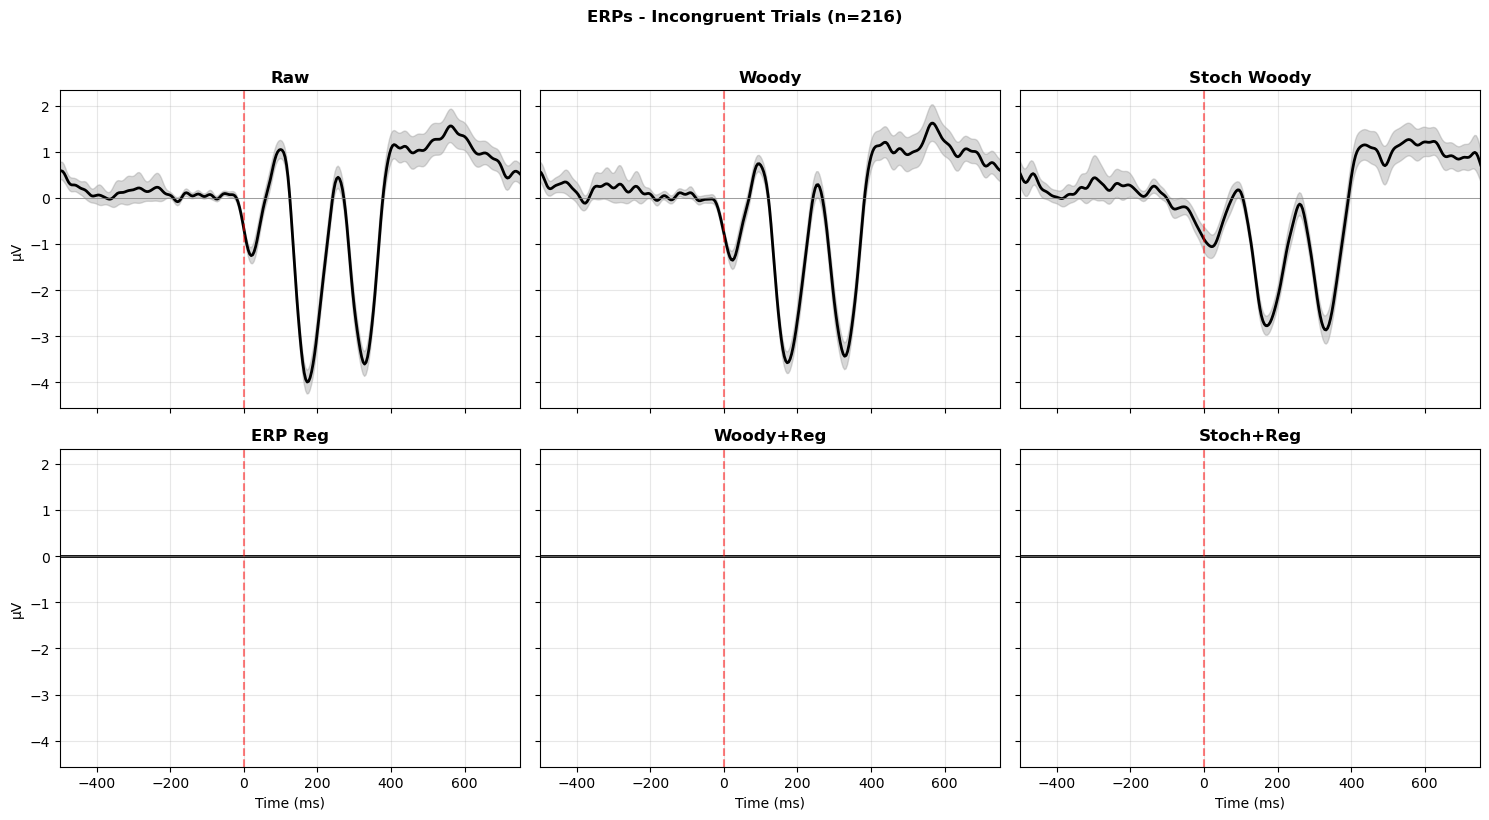

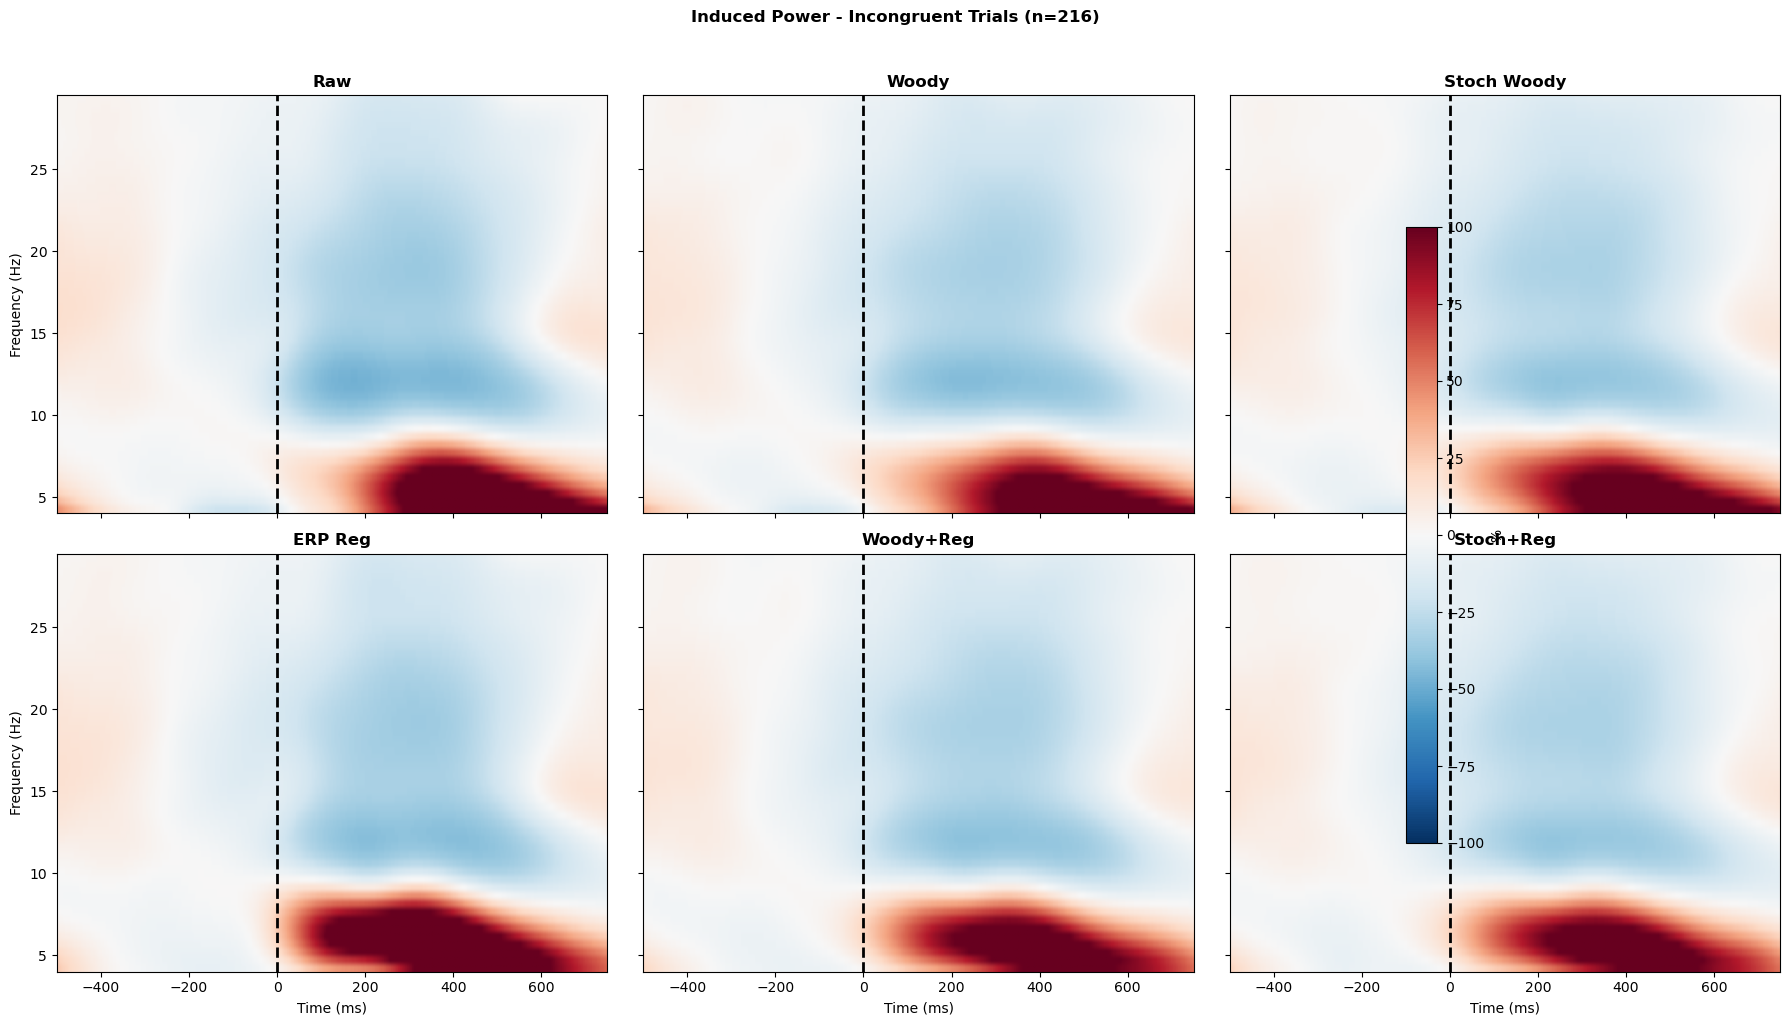

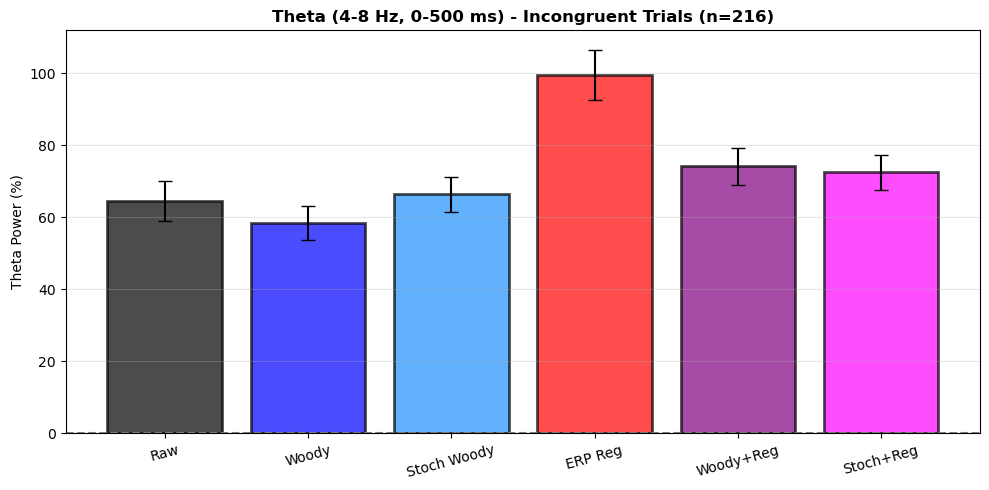

In [6]:
df_incongruent = plot_group_results(results_incongruent, 'Incongruent Trials')

Raw: 32.3 ± 3.3%
Woody: 31.1 ± 3.4%
Stoch Woody: 38.6 ± 3.4%
ERP Reg: 74.3 ± 7.9%
Woody+Reg: 43.2 ± 3.9%
Stoch+Reg: 42.1 ± 3.3%


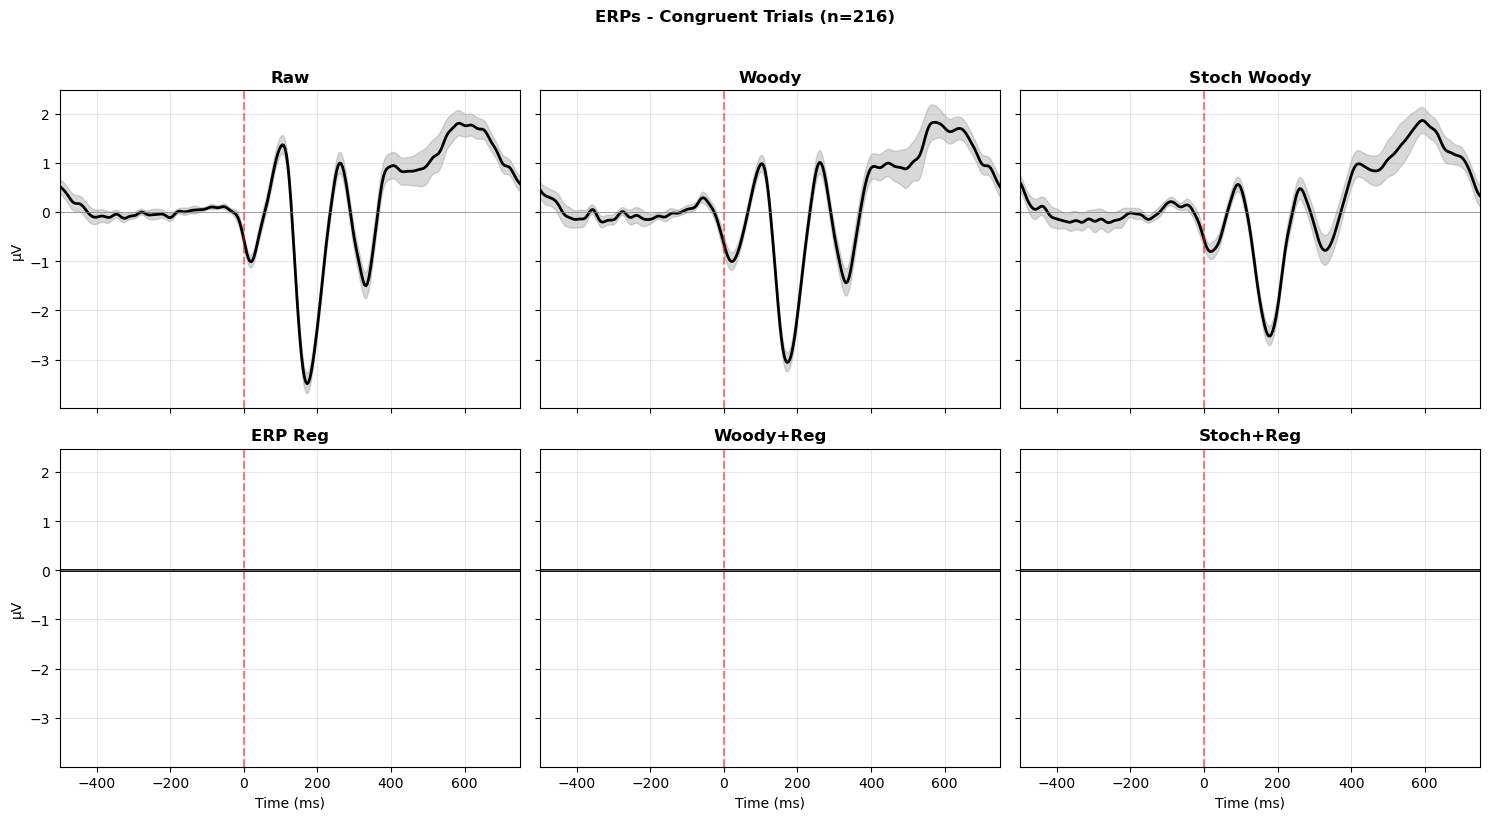

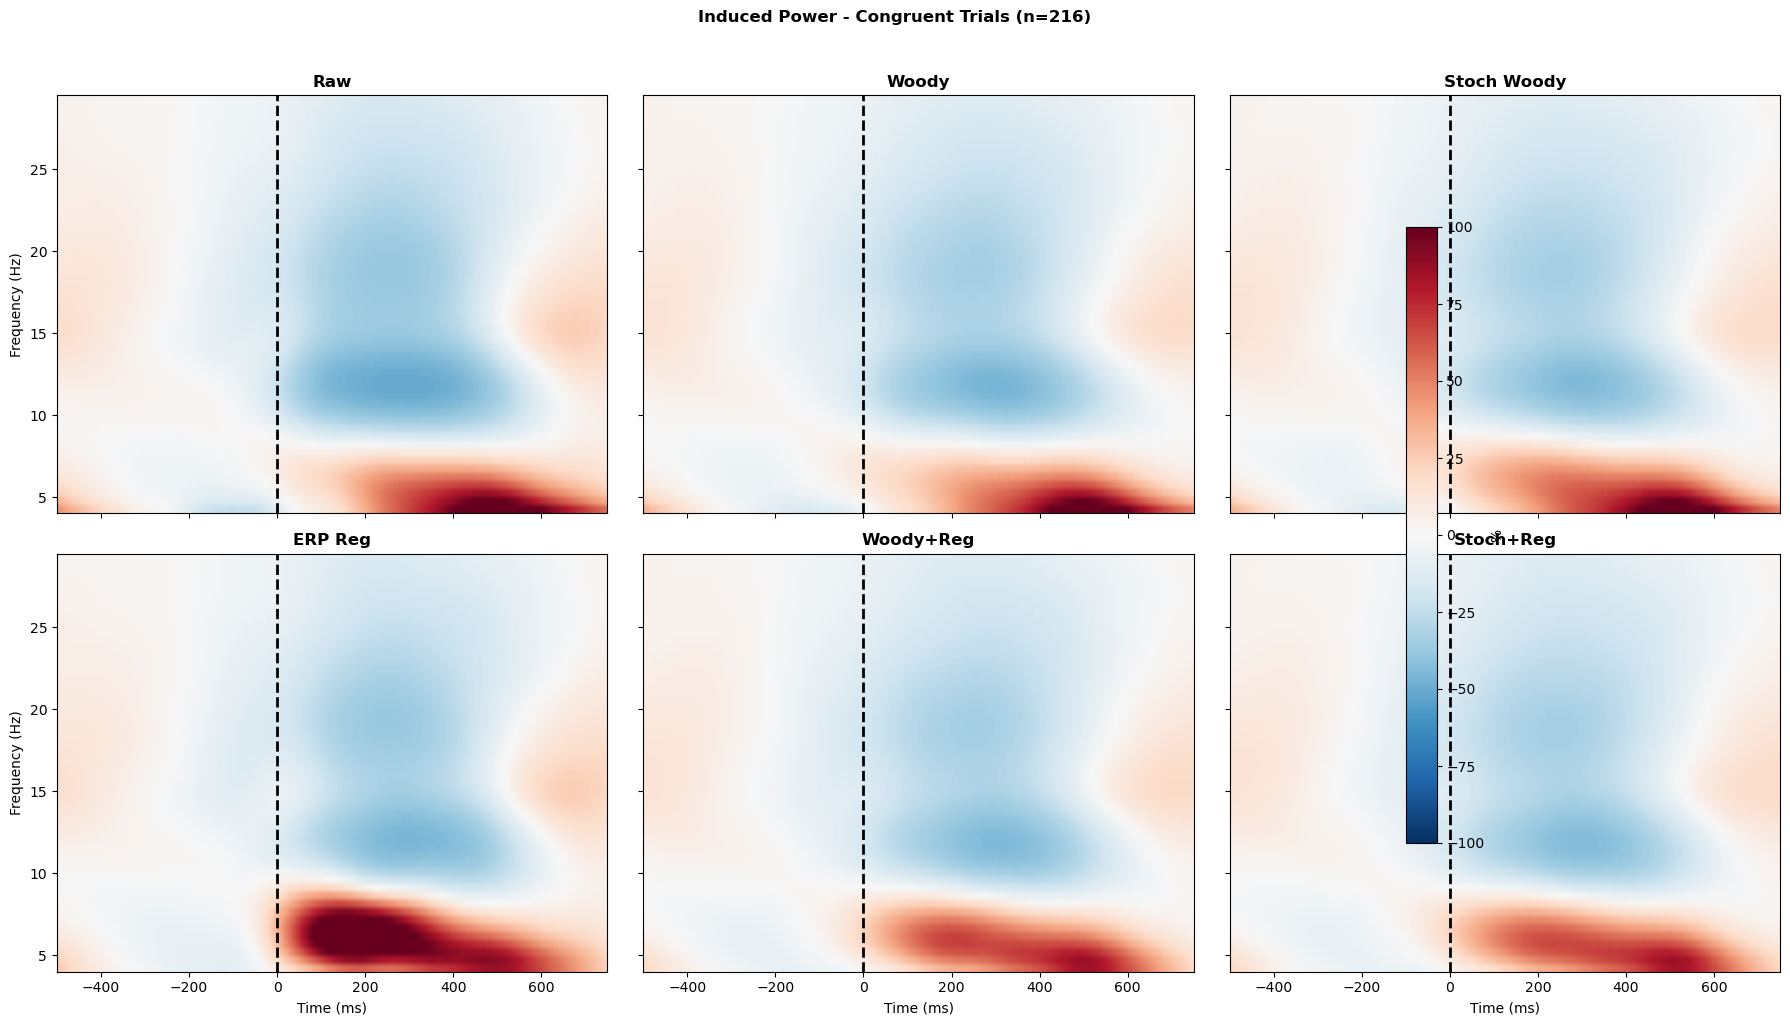

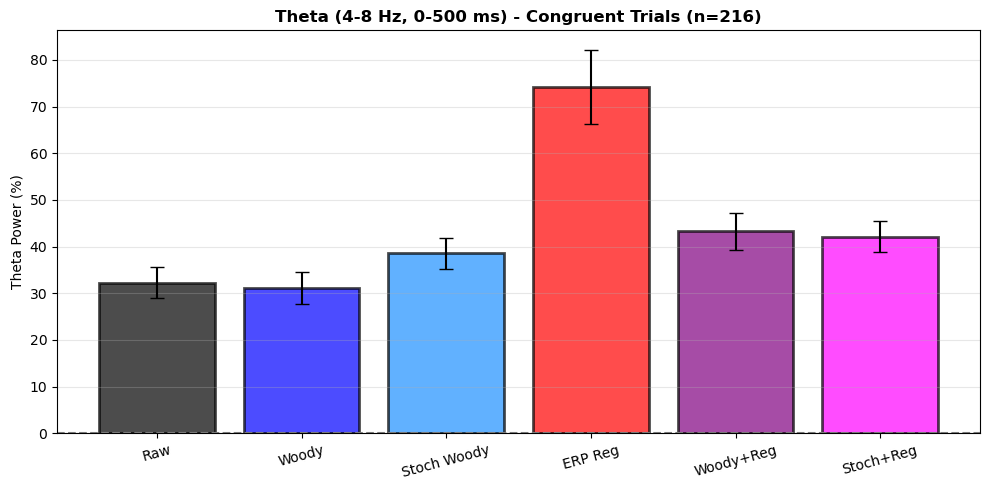

In [ ]:
df_congruent = plot_group_results(results_congruent, 'Congruent Trials')

In [21]:
def plot_group_results(results, title_suffix):
    times = results[0]['times']
    freqs = results[0]['freqs']
    n = len(results)
    
    erp_keys = ['erp_raw', 'erp_sw_reg']
    tfr_keys = ['tfr_raw', 'tfr_sw_reg']
    labels = ['Raw', 'Stoch+Reg']
    colors = ['black', 'magenta']
    
    # ERPs
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
    for i, (key, label) in enumerate(zip(erp_keys, labels)):
        erp_all = np.array([r[key] for r in results])
        m, sem = erp_all.mean(0), erp_all.std(0) / np.sqrt(n)
        axes[i].plot(times * 1000, m, color=colors[i], lw=2)
        axes[i].fill_between(times * 1000, m - sem, m + sem, color=colors[i], alpha=0.2)
        axes[i].axvline(0, color='r', ls='--', alpha=0.5)
        axes[i].axhline(0, color='gray', lw=0.5)
        axes[i].set_xlim(-500, 750)
        axes[i].set_title(label, fontweight='bold')
        axes[i].set_xlabel('Time (ms)')
        axes[i].grid(alpha=0.3)
        if i == 0: axes[i].set_ylabel('µV')
    plt.suptitle(f'ERPs - {title_suffix} (n={n})', fontweight='bold', y=1.02)
    plt.tight_layout()
    
    # TFRs
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
    for i, (key, label) in enumerate(zip(tfr_keys, labels)):
        tfr_all = np.array([r[key] for r in results])
        m = tfr_all.mean(0)
        im = axes[i].imshow(m, aspect='auto', origin='lower',
                            extent=[times[0]*1000, times[-1]*1000, freqs[0], freqs[-1]],
                            vmin=-100, vmax=100, cmap='RdBu_r')
        plt.colorbar(im, ax=axes[i], label='%')
        axes[i].axvline(0, color='k', ls='--', lw=2)
        axes[i].set_xlim(-500, 750)
        axes[i].set_title(label, fontweight='bold')
        axes[i].set_xlabel('Time (ms)')
        if i == 0: axes[i].set_ylabel('Frequency (Hz)')
    plt.suptitle(f'Induced Power - {title_suffix} (n={n})', fontweight='bold', y=1.02)
    plt.tight_layout()
    
    # Theta bars
    df = pd.DataFrame([{k: v for k, v in r.items() if not isinstance(v, np.ndarray)} for r in results])
    theta_cols = ['theta_raw', 'theta_sw_reg']
    
    fig, ax = plt.subplots(figsize=(5, 5))
    means = [df[c].mean() for c in theta_cols]
    sems = [df[c].sem() for c in theta_cols]
    ax.bar(range(2), means, yerr=sems, color=colors, alpha=0.7, edgecolor='k', lw=2, capsize=5)
    ax.set_xticks(range(2))
    ax.set_xticklabels(labels, rotation=15)
    ax.axhline(0, color='gray', ls='--')
    ax.set_ylabel('Theta Power (%)')
    ax.set_title(f'Theta (4-8 Hz, 0-600 ms) - {title_suffix} (n={n})', fontweight='bold')
    ax.grid(alpha=0.3, axis='y')
    plt.tight_layout()
    
    for l, m, s in zip(labels, means, sems):
        print(f'{l}: {m:.1f} ± {s:.1f}%')
    
    return df

Raw: 32.3 ± 3.3%
Stoch+Reg: 42.1 ± 3.3%


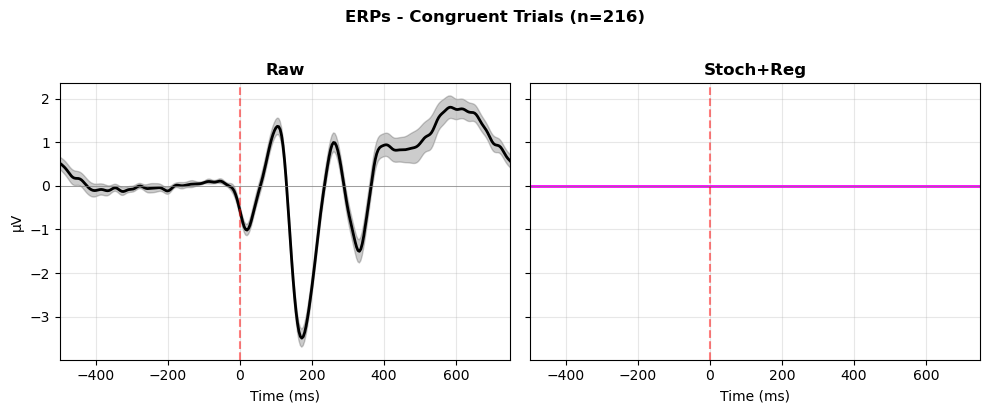

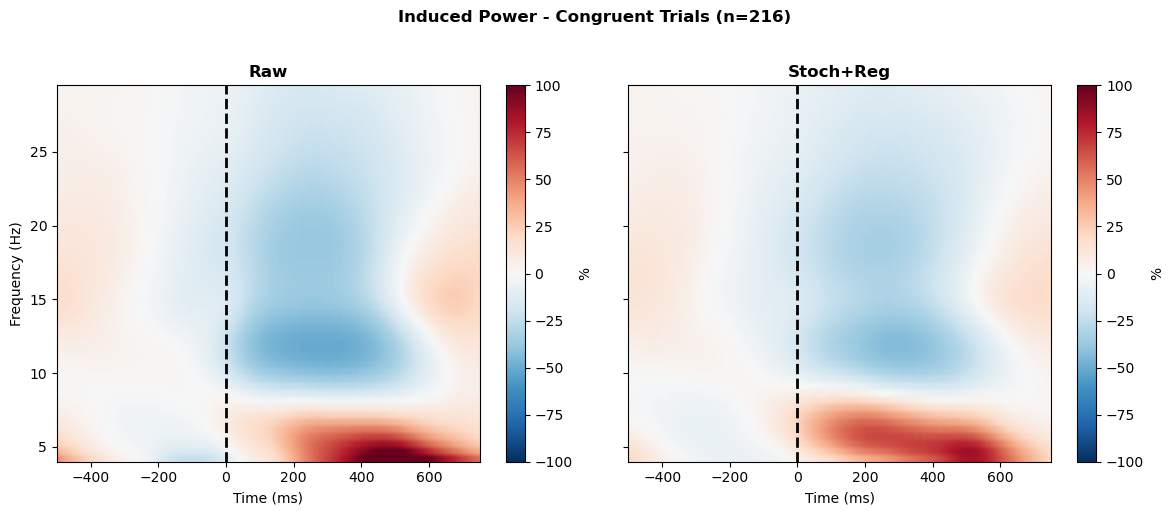

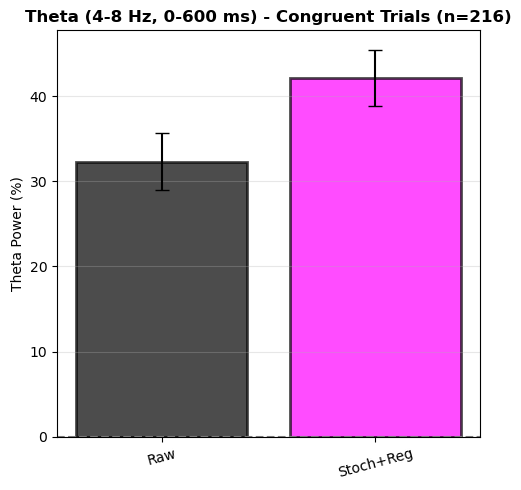

In [24]:
df_incongruent = plot_group_results(results_congruent, 'Congruent Trials')

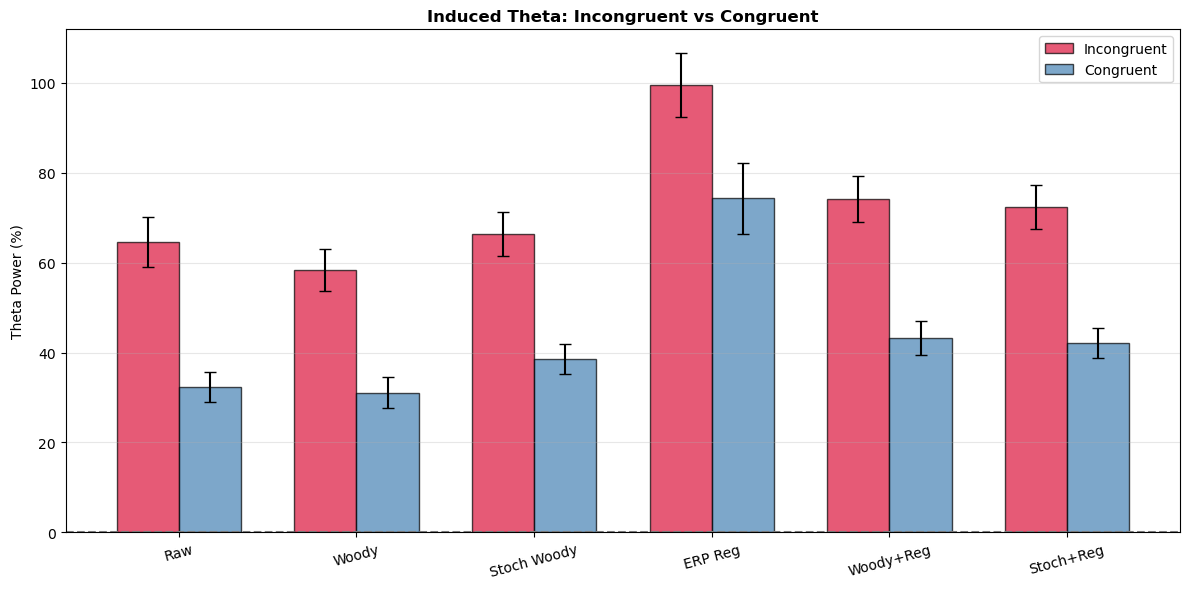

In [8]:
# Incongruent vs Congruent comparison
labels = ['Raw', 'Woody', 'Stoch Woody', 'ERP Reg', 'Woody+Reg', 'Stoch+Reg']
theta_cols = ['theta_raw', 'theta_w', 'theta_sw', 'theta_reg', 'theta_w_reg', 'theta_sw_reg']

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(6)
width = 0.35

means_inc = [df_incongruent[c].mean() for c in theta_cols]
sems_inc = [df_incongruent[c].sem() for c in theta_cols]
means_cong = [df_congruent[c].mean() for c in theta_cols]
sems_cong = [df_congruent[c].sem() for c in theta_cols]

ax.bar(x - width/2, means_inc, width, yerr=sems_inc, label='Incongruent', color='crimson', alpha=0.7, edgecolor='k', capsize=4)
ax.bar(x + width/2, means_cong, width, yerr=sems_cong, label='Congruent', color='steelblue', alpha=0.7, edgecolor='k', capsize=4)

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=15)
ax.axhline(0, color='gray', ls='--')
ax.set_ylabel('Theta Power (%)')
ax.set_title('Induced Theta: Incongruent vs Congruent', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()

In [9]:
def analyze_lhac(epochs_path, trial_type='incongruent', freqs_range=np.arange(4, 30, 1), lags_range=np.arange(0.5, 5, 0.25)):
    epochs = mne.read_epochs(epochs_path, preload=True, verbose=False)
    
    if trial_type == 'incongruent':
        codes = ['104']
    else:
        codes = ['134']
    
    epochs_sel = epochs[codes]
    n_trials = len(epochs_sel)
    if n_trials < 10:
        return None
    
    data = epochs_sel.copy().pick(['FZ']).get_data()[:, 0, :] * 1e6
    times = epochs_sel.times
    sfreq = epochs_sel.info['sfreq']
    
    time_mask = (times >= -1) & (times <= 1.5)
    data_crop = data[:, time_mask]
    
    # Raw induced
    erp_raw = data_crop.mean(0)
    induced_raw = data_crop - erp_raw
    
    # Stochastic Woody
    _, lags, _ = woody_stochastic(data.T, tol=0.1, max_it=100, n_runs=1000, max_lag_init=10, xcorr_mthd='unbiased', max_shift=50)
    aligned = align_trials(data, lags)
    aligned_crop = aligned[:, time_mask]
    erp_sw = aligned_crop.mean(0)
    induced_sw = aligned_crop - erp_sw
    
    # Stochastic Woody + Regression
    induced_sw_reg = regress_erp(aligned_crop, erp_sw)
    
    lhc_raw = lagged_hilbert_autocoherence(induced_raw, freqs_range, lags_range, srate=sfreq, df=1.0)
    lhc_sw = lagged_hilbert_autocoherence(induced_sw, freqs_range, lags_range, srate=sfreq, df=1.0)
    lhc_sw_reg = lagged_hilbert_autocoherence(induced_sw_reg, freqs_range, lags_range, srate=sfreq, df=1.0)
    
    return {'lhc_raw': lhc_raw, 'lhc_sw': lhc_sw, 'lhc_sw_reg': lhc_sw_reg, 'n_trials': n_trials}

In [10]:
freqs_range = np.arange(4, 30, 1)
lags_range = np.arange(0.5, 5, 0.25)

lhac_incongruent = []
lhac_congruent = []

for sub_id in tqdm(subjects):
    sub_file = data_dir / f'{sub_id}_target_cong_incong-epo.fif'
    if not sub_file.exists():
        continue
    try:
        res_inc = analyze_lhac(sub_file, 'incongruent', freqs_range, lags_range)
        res_cong = analyze_lhac(sub_file, 'congruent', freqs_range, lags_range)
        if res_inc:
            lhac_incongruent.append(res_inc)
        if res_cong:
            lhac_congruent.append(res_cong)
    except:
        continue

print(f'LHaC - Incongruent: {len(lhac_incongruent)}, Congruent: {len(lhac_congruent)}')

100%|██████████| 221/221 [2:34:14<00:00, 41.88s/it]  

LHaC - Incongruent: 216, Congruent: 216


Theta LHaC - Raw: 0.125, SW: 0.131, SW+Reg: 0.129


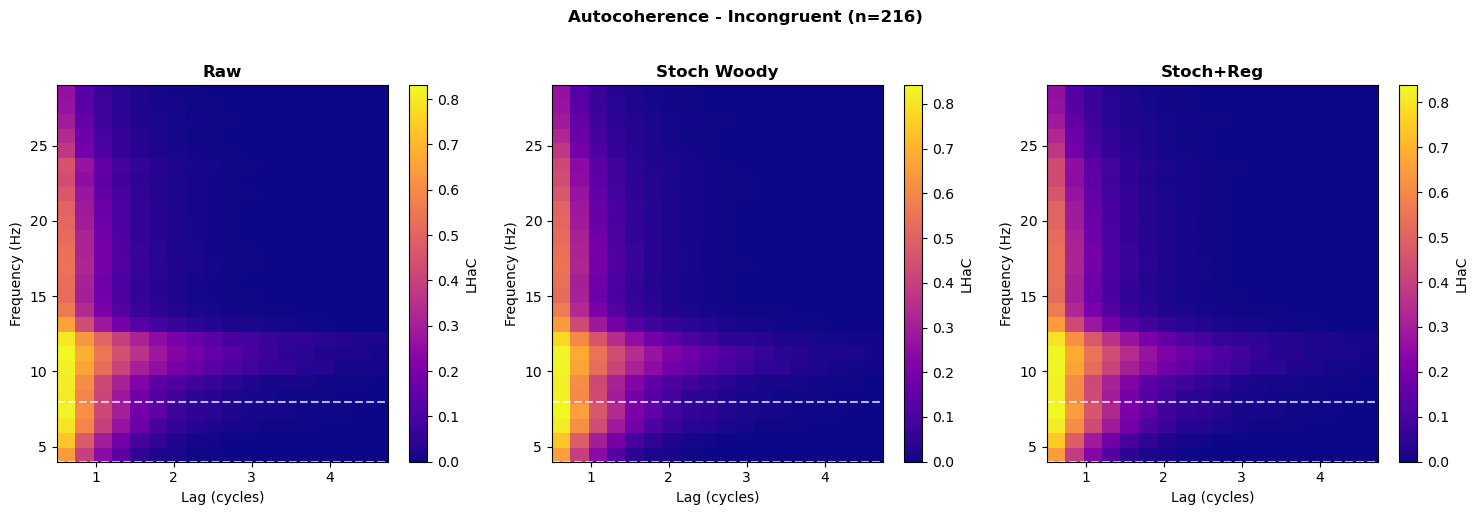

In [11]:
def plot_lhac(results, title_suffix, freqs_range, lags_range):
    lhc_raw = np.array([r['lhc_raw'].mean(0) for r in results]).mean(0)
    lhc_sw = np.array([r['lhc_sw'].mean(0) for r in results]).mean(0)
    lhc_sw_reg = np.array([r['lhc_sw_reg'].mean(0) for r in results]).mean(0)
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, lhc, label in zip(axes, [lhc_raw, lhc_sw, lhc_sw_reg], ['Raw', 'Stoch Woody', 'Stoch+Reg']):
        im = ax.imshow(lhc, aspect='auto', origin='lower', cmap='plasma',
                       extent=[lags_range[0], lags_range[-1], freqs_range[0], freqs_range[-1]])
        ax.axhline(4, color='w', ls='--', lw=1.5, alpha=0.7)
        ax.axhline(8, color='w', ls='--', lw=1.5, alpha=0.7)
        ax.set_xlabel('Lag (cycles)')
        ax.set_ylabel('Frequency (Hz)')
        ax.set_title(label, fontweight='bold')
        plt.colorbar(im, ax=ax, label='LHaC')
    plt.suptitle(f'Autocoherence - {title_suffix} (n={len(results)})', fontweight='bold', y=1.02)
    plt.tight_layout()
    
    theta_mask = (freqs_range >= 4) & (freqs_range <= 8)
    print(f'Theta LHaC - Raw: {lhc_raw[theta_mask].mean():.3f}, SW: {lhc_sw[theta_mask].mean():.3f}, SW+Reg: {lhc_sw_reg[theta_mask].mean():.3f}')

plot_lhac(lhac_incongruent, 'Incongruent', freqs_range, lags_range)

Theta LHaC - Raw: 0.117, SW: 0.123, SW+Reg: 0.122


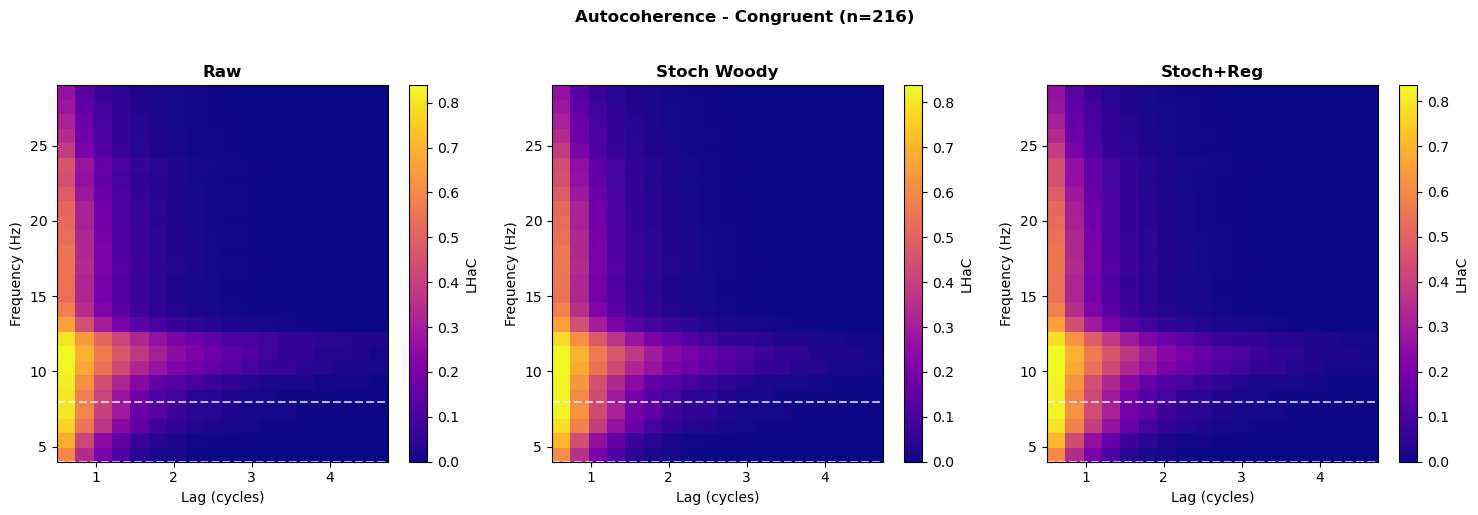

In [12]:
plot_lhac(lhac_congruent, 'Congruent', freqs_range, lags_range)

In [13]:
df_incongruent.to_csv('theta_analysis_incongruent.csv', index=False)
df_congruent.to_csv('theta_analysis_congruent.csv', index=False)
print('Saved')

Saved
